In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv("student_placement_prediction_dataset_2026.csv")

In [ ]:
df.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [ ]:
df.columns

Index(['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier',
       'internships_count', 'projects_count', 'certifications_count',
       'coding_skill_score', 'aptitude_score', 'communication_skill_score',
       'logical_reasoning_score', 'hackathons_participated', 'github_repos',
       'linkedin_connections', 'mock_interview_score', 'attendance_percentage',
       'backlogs', 'extracurricular_score', 'leadership_score',
       'volunteer_experience', 'sleep_hours', 'study_hours_per_day',
       'placement_status', 'salary_package_lpa'],
      dtype='object')

In [ ]:
df.shape

(100000, 26)

In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
cgpa,0
branch,0
college_tier,0
internships_count,0
projects_count,0
certifications_count,0
coding_skill_score,0


In [ ]:
df['placement_status'].value_counts()

,count
placement_status,
Placed,54459
Not Placed,45541


In [ ]:
df['cgpa'].mean()

np.float64(7.4968902)

In [ ]:
df.groupby('placement_status')['cgpa'].mean()

,cgpa
placement_status,
Not Placed,7.483789
Placed,7.507846


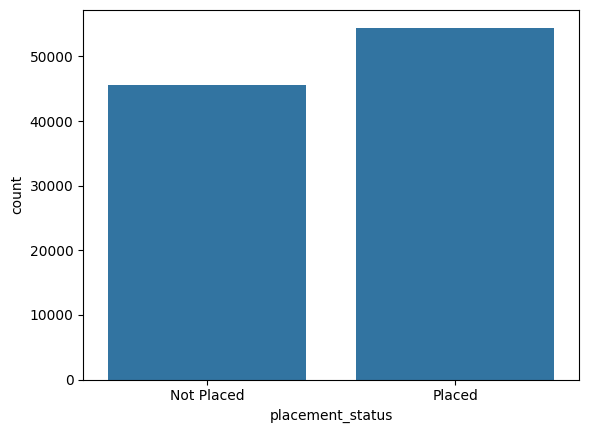

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='placement_status',data=df)
plt.show()

In [ ]:
df.groupby('placement_status')['internshios_count'].mean()

,internships_count
placement_status,
Not Placed,1.417163
Placed,1.573367


In [ ]:
df.groupby('placement_status')['projects_count'].mean()

,projects_count
placement_status,
Not Placed,2.886410
Placed,3.098404


In [ ]:
df.groupby('placement_status')['coding_skill_score'].mean()

<bound method GroupBy.mean of <pandas.core.groupby.generic.SeriesGroupBy object at 0x7b0a97116690>>

In [ ]:
df.groupby('placement_status')['mock_interview_score'].mean()

,mock_interview_score
placement_status,
Not Placed,69.388182
Placed,70.492185


In [3]:
import os

os.listdir()

['.config', 'student_placement_prediction_dataset_2026.csv', 'sample_data']

In [6]:
import pandas as pd

df = pd.read_csv('student_placement_prediction_dataset_2026.csv')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   student_id                 100000 non-null  int64  
 1   age                        100000 non-null  int64  
 2   gender                     100000 non-null  object 
 3   cgpa                       100000 non-null  float64
 4   branch                     100000 non-null  object 
 5   college_tier               100000 non-null  object 
 6   internships_count          100000 non-null  int64  
 7   projects_count             100000 non-null  int64  
 8   certifications_count       100000 non-null  int64  
 9   coding_skill_score         100000 non-null  float64
 10  aptitude_score             100000 non-null  float64
 11  communication_skill_score  100000 non-null  float64
 12  logical_reasoning_score    100000 non-null  float64
 13  hackathons_participated    100

In [8]:
df['placement_status'] = df['placement_status'].map({
    'placed':1,
    'not placed':0
})

In [9]:
df['placement_status'].head()

,placement_status
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN


In [10]:
df = pd.get_dummies(df,
                    columns=[
                        'gender',
                        'branch',
                        'college_tier',
                        'volunteer_experience'
                    ],
                    drop_first=True)

In [11]:
x = df.drop(['placement_status'],axis=1)

y = df['placement_status']

In [12]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# 1. Reload the dataset to get original placement_status values
df = pd.read_csv('student_placement_prediction_dataset_2026.csv')

# 2. Map correctly using matching capitalization ('Placed' / 'Not Placed')
df['placement_status'] = df['placement_status'].map({
    'Placed': 1,
    'Not Placed': 0
})

# 3. Apply dummy encoding
df = pd.get_dummies(df,
                    columns=[
                        'gender',
                        'branch',
                        'college_tier',
                        'volunteer_experience'
                    ],
                    drop_first=True)

# 4. Separate features and target
x = df.drop(['placement_status'], axis=1)
y = df['placement_status']

# 5. Split dataset
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

# 6. Initialize and fit the Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)
print("Model trained successfully!")

Model trained successfully!


Accuracy Score: 100.0000%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9127
           1       1.00      1.00      1.00     10873

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



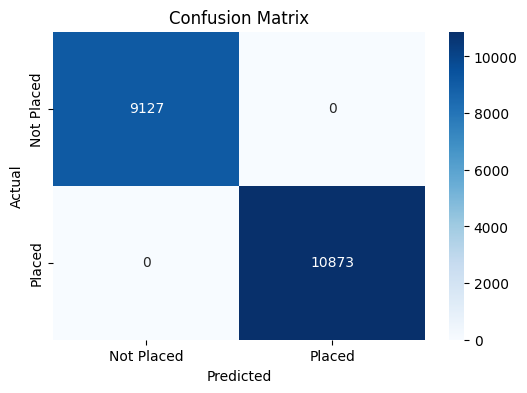

In [16]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Make predictions on the test set
y_pred = model.predict(x_test)

# Calculate and print metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [17]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

1.0

In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9127
           1       1.00      1.00      1.00     10873

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



In [19]:
importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': model.coef_[0]
})

importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

,Feature,Importance
20,salary_package_lpa,2.308756
4,projects_count,0.029745
16,extracurricular_score,0.026557
3,internships_count,0.021402
7,aptitude_score,0.021276
8,communication_skill_score,0.009259
13,mock_interview_score,0.001529
22,branch_Civil,0.000248
28,college_tier_Tier 3,0.000139
0,student_id,-0.000002


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(x_train, y_train)

pred = rf.predict(x_test)

accuracy_score(y_test, pred)

1.0

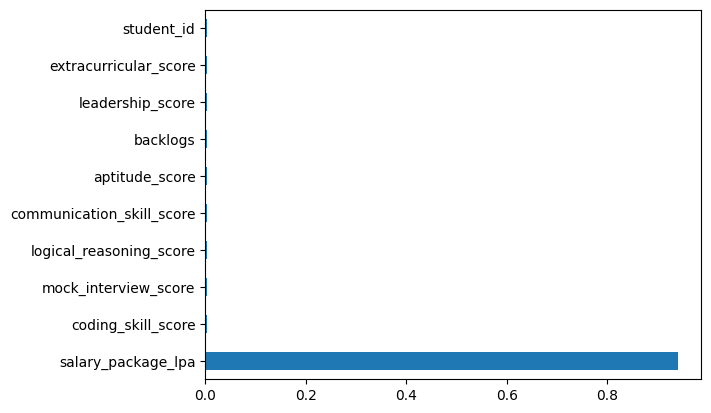

In [23]:
import matplotlib.pyplot as plt

feature_imp = pd.Series(
    rf.feature_importances_,
    index=x.columns
)

feature_imp.sort_values(
    ascending=False
).head(10).plot(
    kind='barh'
)

plt.show()